# Logistics Delivery Analysis
### Week 1: Strategic Planning and Data Exploration

**Dataset:** Delivery_Logistics.csv (25,000 deliveries, 15 columns)
**Goal:** Understand why deliveries are delayed and what decides delivery cost.

## Step 1: Load and Clean the Data

In [2]:
import pandas as pd

df = pd.read_csv("C:\\Users\\sarna\\Downloads\\Delivery_Logistics.csv")

# Fix the time columns: the last digits are the hours
df["delivery_time_hours"] = df["delivery_time_hours"].str[-9:].astype(int)
df["expected_time_hours"] = df["expected_time_hours"].str[-9:].astype(int)

print(df.shape)
df.head()

(25000, 15)


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250.99,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250.99,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250.99,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600


## Step 2: Calculate the KPIs

In [3]:
# KPI 1: On-time delivery rate (%)
on_time_rate = (df["delayed"] == "no").mean() * 100

# KPI 2: Average delivery cost
avg_cost = df["delivery_cost"].mean()

# KPI 3: Average delivery rating
avg_rating = df["delivery_rating"].mean()

# Extra KPI: Failed delivery rate (%)
failed_rate = (df["delivery_status"] == "failed").mean() * 100

print("On-time delivery rate:", round(on_time_rate, 1), "%")
print("Average delivery cost:", round(avg_cost, 0))
print("Average rating:", round(avg_rating, 2))
print("Failed delivery rate:", round(failed_rate, 1), "%")

On-time delivery rate: 73.3 %
Average delivery cost: 865.0
Average rating: 3.67
Failed delivery rate: 5.3 %


## KPI Results

| KPI | Value |
|---|---|
| On-time delivery rate | 73.3% |
| Average delivery cost | ₹865 |
| Average delivery rating | 3.67 / 5 |
| Failed delivery rate | 5.3% |

**Insight:** About 1 in 4 deliveries (26.7%) arrives late, and 5.3% of deliveries fail completely. The company can improve its service by finding out what causes these delays.

## Step 3: Delay Rate by Delivery Mode

In [4]:
# Delay rate (%) for each delivery mode
delay_by_mode = (df["delayed"] == "yes").groupby(df["delivery_mode"]).mean() * 100
print(delay_by_mode.round(1))

delivery_mode
express     73.8
same day    32.5
standard     0.0
two day      0.4
Name: delayed, dtype: float64


## Delay Rate by Delivery Mode

| Delivery Mode | Delay Rate |
|---|---|
| Express | 73.8% |
| Same day | 32.5% |
| Two day | 0.4% |
| Standard | 0.0% |

**Insight:** Express deliveries are delayed the most (about 3 in 4), followed by same day deliveries. Standard and two day deliveries are almost never late. This shows that the faster the promised delivery, the harder it is to deliver on time.

## Step 4: How Distance and Weight Affect Cost

In [5]:
# How strongly are distance, weight and cost connected?
print(df[["distance_km", "package_weight_kg", "delivery_cost"]].corr().round(2))

                   distance_km  package_weight_kg  delivery_cost
distance_km               1.00                0.0           0.99
package_weight_kg         0.00                1.0           0.10
delivery_cost             0.99                0.1           1.00


## Step 5: Predict Delivery Cost (Regression)

In [6]:
from sklearn.linear_model import LinearRegression

# Input (X) and the thing we want to predict (y)
X = df[["distance_km"]]
y = df["delivery_cost"]

# Train the model
model = LinearRegression()
model.fit(X, y)

# Predict the cost of a 100 km delivery
prediction = model.predict(pd.DataFrame({"distance_km": [100]}))
print("Cost for 100 km:", round(prediction[0], 0))
print("Accuracy score (R2):", round(model.score(X, y), 2))

Cost for 100 km: 613.0
Accuracy score (R2): 0.98


## Regression Result

| Result | Value |
|---|---|
| Predicted cost for a 100 km delivery | ₹613 |
| Accuracy score (R2) | 0.98 |

**Insight:** A simple regression model can predict delivery cost from distance alone with 98% accuracy. This helps a company estimate the price of a delivery before it is made and plan its budget.

## Step 6: Group Similar Deliveries (Clustering)

In [9]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
from sklearn.cluster import KMeans

# Group deliveries by distance and weight
X = df[["distance_km", "package_weight_kg"]]

model = KMeans(n_clusters=3, random_state=42, n_init=10)
df["group"] = model.fit_predict(X)

# See what each group looks like
print(df.groupby("group")[["distance_km", "package_weight_kg", "delivery_cost"]].mean().round(1))

       distance_km  package_weight_kg  delivery_cost
group                                               
0            152.1               25.2          873.7
1             51.3               25.0          369.4
2            251.3               25.2         1369.4


## Clustering Result

| Group | Type | Avg Distance | Avg Weight | Avg Cost |
|---|---|---|---|---|
| 1 | Short deliveries | 51 km | 25 kg | ₹369 |
| 0 | Medium deliveries | 152 km | 25 kg | ₹874 |
| 2 | Long deliveries | 251 km | 25 kg | ₹1,369 |

**Insight:** The deliveries naturally split into three groups: short, medium, and long. The groups differ mostly by distance, and the average cost rises with each one. A company could use these groups to plan vehicles, set prices, and assign delivery partners.

## Step 7: Chart of Delays by Delivery Mode

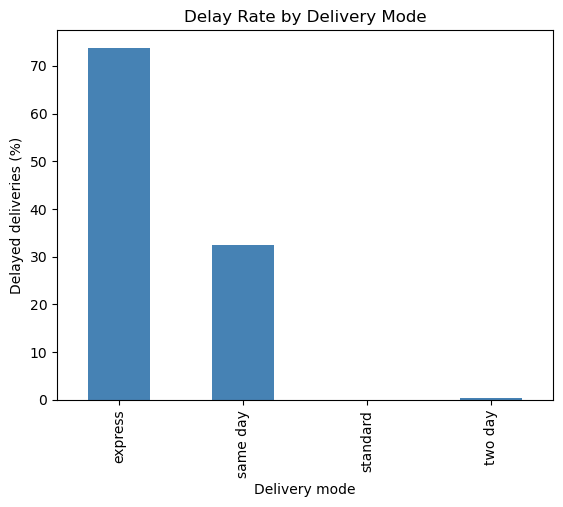

In [10]:
import matplotlib.pyplot as plt

delay_by_mode = (df["delayed"] == "yes").groupby(df["delivery_mode"]).mean() * 100

delay_by_mode.plot(kind="bar", color="steelblue")
plt.title("Delay Rate by Delivery Mode")
plt.ylabel("Delayed deliveries (%)")
plt.xlabel("Delivery mode")
plt.show()

## Chart Result

**Insight:** The chart shows clearly that express deliveries are late most often, followed by same day deliveries. Standard and two day deliveries are almost never late. To reduce delays, the company should focus on its express and same day services.